# Notebook for the evaluation of Trained Default Prediction Models 

# Upload and prepare data

In [1]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path().resolve().parent.parent / "data" / "aprobados-negados"
data_file = "merged_df.csv"

file_path = DATA_DIR / data_file

df = pd.read_csv(file_path, sep=";")
df.head()

,Unnamed: 0,n.credito,cartera,plazo,vinculacion,v.cuota,v.prestamo,s.capital,s.intereses,aportes,...,curtotalingresos,curtotalegresos,intestrato,actualización,default,puntaje_data,grupo_dptmto,grupo_ciudad,grupo_edad,grupo_actividadeco
0,0,003-002-0125852-7,consumo_sin_libranza,1827,8103,356849.0,15000000.0,12923538.0,123855,7741255,...,4597000.0,1500000.0,5.0,1.0,0.0,795.0,3.0,1.0,3.0,4.0
1,1,004-002-0068475-5,consumo_sin_libranza,1826,1434,2650409.0,100460000.0,31911361.0,263265,4601706,...,4597000.0,650000.0,5.0,1.0,0.0,836.0,3.0,5.0,3.0,4.0
2,2,003-002-0122592-9,consumo_sin_libranza,1826,573,791482.0,30000000.0,23844684.0,261477,530431,...,4400000.0,2000000.0,4.0,0.0,1.0,709.0,3.0,7.0,2.0,4.0
3,3,006-002-0023879-0,consumo_sin_libranza,2922,1902,2860501.0,176000000.0,113842595.0,1008570,3023534,...,22020000.0,1500000.0,4.0,1.0,0.0,733.0,3.0,6.0,3.0,1.0
4,4,006-002-0026159-4,consumo_sin_libranza,2557,1902,987637.0,50300000.0,38521256.0,317167,1023082,...,22020000.0,1500000.0,4.0,1.0,0.0,695.0,3.0,6.0,3.0,1.0


In [2]:
df = df.drop(columns=["Unnamed: 0"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12861 entries, 0 to 12860
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   n.credito           12861 non-null  object 
 1   cartera             12861 non-null  object 
 2   plazo               12861 non-null  int64  
 3   vinculacion         12861 non-null  int64  
 4   v.cuota             12861 non-null  float64
 5   v.prestamo          12861 non-null  float64
 6   s.capital           12861 non-null  float64
 7   s.intereses         12861 non-null  int64  
 8   aportes             12861 non-null  int64  
 9   morosidad           12861 non-null  int64  
 10  garantias           12861 non-null  int64  
 11  valorgarantia       12861 non-null  int64  
 12  reestr              12861 non-null  int64  
 13  ctasahorros         12861 non-null  object 
 14  edad                12861 non-null  float64
 15  tipoasociado        12861 non-null  int64  
 16  acti

In [3]:
df['cartera'].value_counts()

cartera
consumo_sin_libranza    7493
consumo_con_libranza    5368
Name: count, dtype: int64

In [5]:
df = df.rename(columns={"actualización": "actualizacion"})
df = df.drop(columns=[
        "morosidad",
        #"cartera",
        "grupo_dptmto",
        "grupo_ciudad",
        "grupo_edad",
        "grupo_actividadeco",
        "actualizacion",
        "s.intereses",
        "estado_cliente"
    ], axis=1,)

df.columns = df.columns.str.replace(".", "_", regex=False)
df.columns = df.columns.str.replace(":", "_", regex=False)
df.columns = df.columns.str.replace(" ", "_", regex=False)
df.set_index("n_credito", inplace=True)
df.head()

,cartera,plazo,vinculacion,v_cuota,v_prestamo,s_capital,aportes,garantias,valorgarantia,reestr,...,tipoasociado,actividadeconomica,departamento,ciudad,sexo,curtotalingresos,curtotalegresos,intestrato,default,puntaje_data
n_credito,,,,,,,,,,,,,,,,,,,,,
003-002-0125852-7,consumo_sin_libranza,1827,8103,356849.0,15000000.0,12923538.0,7741255,1,7741255,4,...,1,asalariados,antioquia,bolivariana,0.0,4597000.0,1500000.0,5.0,0.0,795.0
004-002-0068475-5,consumo_sin_libranza,1826,1434,2650409.0,100460000.0,31911361.0,4601706,1,4601706,4,...,1,asalariados,antioquia,envigado,0.0,4597000.0,650000.0,5.0,0.0,836.0
003-002-0122592-9,consumo_sin_libranza,1826,573,791482.0,30000000.0,23844684.0,530431,1,530431,4,...,1,asalariados,antioquia,medellin,0.0,4400000.0,2000000.0,4.0,1.0,709.0
006-002-0023879-0,consumo_sin_libranza,2922,1902,2860501.0,176000000.0,113842595.0,3023534,2,320385440,4,...,1,educacion_basica_secundaria,antioquia,rionegro,0.0,22020000.0,1500000.0,4.0,0.0,733.0
006-002-0026159-4,consumo_sin_libranza,2557,1902,987637.0,50300000.0,38521256.0,1023082,2,320385440,4,...,1,educacion_basica_secundaria,antioquia,rionegro,0.0,22020000.0,1500000.0,4.0,0.0,695.0


In [6]:
df.isna().sum().sort_values(ascending=False)

ciudad                10
actividadeconomica     9
departamento           5
default                4
sexo                   4
curtotalingresos       4
puntaje_data           4
curtotalegresos        4
intestrato             4
v_prestamo             0
plazo                  0
cartera                0
v_cuota                0
vinculacion            0
s_capital              0
tipoasociado           0
ctasahorros            0
edad                   0
garantias              0
valorgarantia          0
aportes                0
reestr                 0
dtype: int64

In [12]:
df = df.dropna(subset=['default'])

For assembly models, all available features will be used, including text strings, and no preprocessing, null data management, or categorical variable encoding will be performed.

In [13]:
# =====================================================================
# MODIFICACIÓN OOT: Extracción del consecutivo y partición secuencial
# =====================================================================

# 1. Extraer el identificador secuencial de originación del crédito
df['credit_id_seq'] = df.index.to_series().apply(
    lambda x: int(str(x).split('-')[2]) if isinstance(x, str) and len(str(x).split('-')) >= 3 else None
)

# 2. Ordenar todo el dataframe cronológicamente usando el proxy secuencial
df = df.sort_values(by='credit_id_seq')

# 3. Separar features y variable objetivo
X = df.drop(["default", "credit_id_seq"], axis=1) # Removemos el ID secuencial para evitar sesgar el modelo
y = df["default"]

# 4. Ajustar tipo de variables categóricas
categorical_features = X.select_dtypes(include="object").columns.to_list()
X[categorical_features] = X[categorical_features].astype("category")

# 5. Partición OOT (80% histórico para entrenamiento, 20% reciente para pruebas)
train_size = int(len(df) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print(f"Total de registros: {len(df)}")
print(f"Registros de entrenamiento (Histórico): {len(X_train)}")
print(f"Registros de prueba (Reciente): {len(X_test)}")

Total de registros: 12857
Registros de entrenamiento (Histórico): 10285
Registros de prueba (Reciente): 2572


In [10]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10288 entries, 006-002-0011475-3 to 002-002-0132598-3
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   cartera             10288 non-null  category
 1   plazo               10288 non-null  int64   
 2   vinculacion         10288 non-null  int64   
 3   v_cuota             10288 non-null  float64 
 4   v_prestamo          10288 non-null  float64 
 5   s_capital           10288 non-null  float64 
 6   aportes             10288 non-null  int64   
 7   garantias           10288 non-null  int64   
 8   valorgarantia       10288 non-null  int64   
 9   reestr              10288 non-null  int64   
 10  ctasahorros         10288 non-null  category
 11  edad                10288 non-null  float64 
 12  tipoasociado        10288 non-null  int64   
 13  actividadeconomica  10281 non-null  category
 14  departamento        10283 non-null  category
 15  ciudad       

In [11]:
categorical_features

['cartera', 'ctasahorros', 'actividadeconomica', 'departamento', 'ciudad']

# Pipelines with Skrub

### Light GBM model with tabular pipeline skrub without hyperparameter tuning

In [18]:
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    verbose=0,
    seed=1,
    feature_fraction_seed=1,
    bagging_seed=1,
    drop_seed=1,
    force_col_wise=True,
    deterministic=True,
    )


model.fit(
    X_train, 
    y_train,
)
    
train_score = f1_score(y_train, model.predict(X_train))
test_score = f1_score(y_test, model.predict(X_test))
print(f"Train score: {train_score:.2f}")
print(f"Test score: {test_score:.2f}")

Train score: 0.90
Test score: 0.34


In [26]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

dist_lgb = {
    'n_estimators': randint(50, 400),
    'max_depth': randint(3, 8),
    'num_leaves': randint(20, 100),
    'learning_rate': loguniform(0.01, 0.3),
    'min_child_samples': randint(10, 50),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-3, 10),
    'reg_lambda': loguniform(1e-3, 10)
}

model = LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    verbose=0,
    seed=1,
    feature_fraction_seed=1,
    bagging_seed=1,
    drop_seed=1,
    force_col_wise=True,
    deterministic=True,
    )


rs_lgb = RandomizedSearchCV(
    estimator=model,
    param_distributions=dist_lgb,
    n_iter=20,
    scoring='roc_auc',
    random_state=1,
    n_jobs=-1
)

rs_lgb.fit(X_train, y_train)

print(f'Validation score: {rs_lgb.best_score_:.3f}')
print(f'Parámetros óptimos: {rs_lgb.best_params_}')
print(f'Train score: {rs_lgb.score(X_train, y_train):.3f}')
print(f'Test score: {rs_lgb.score(X_test, y_test):.3f}')

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

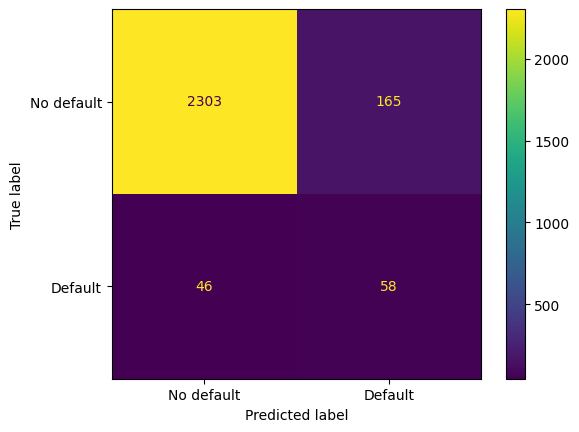

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rs_lgb, 
    X_test, 
    y_test, 
    display_labels=["No default", "Default"]
    )

In [24]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, 
    rs_lgb.predict(X_test), 
    target_names=["No default", "Default"]
    ))

              precision    recall  f1-score   support

  No default       0.98      0.93      0.96      2468
     Default       0.26      0.56      0.35       104

    accuracy                           0.92      2572
   macro avg       0.62      0.75      0.66      2572
weighted avg       0.95      0.92      0.93      2572



In [28]:
lgb_features = pd.DataFrame({
    'Feature': rs_lgb.best_estimator_.feature_names_in_,
    'Importance': rs_lgb.best_estimator_.feature_importances_
})

lgb_features.sort_values('Importance', ascending=False)

,Feature,Importance
2,vinculacion,1716
8,valorgarantia,1203
5,s_capital,1119
20,puntaje_data,1110
17,curtotalingresos,1047
3,v_cuota,773
15,ciudad,741
6,aportes,735
11,edad,698
18,curtotalegresos,673


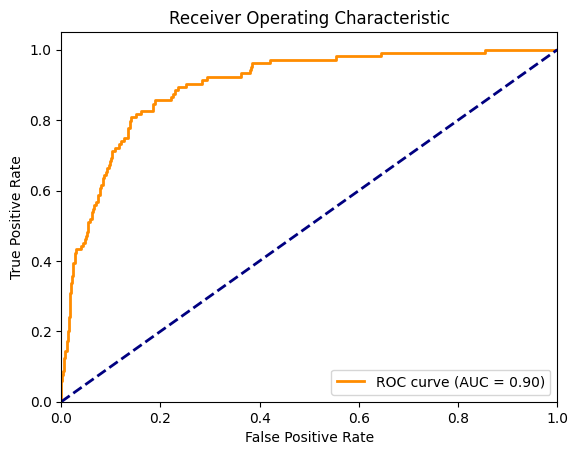

In [29]:
# Hacer curva ROC y calcular AUC
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_curve

y_pred_proba = rs_lgb.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

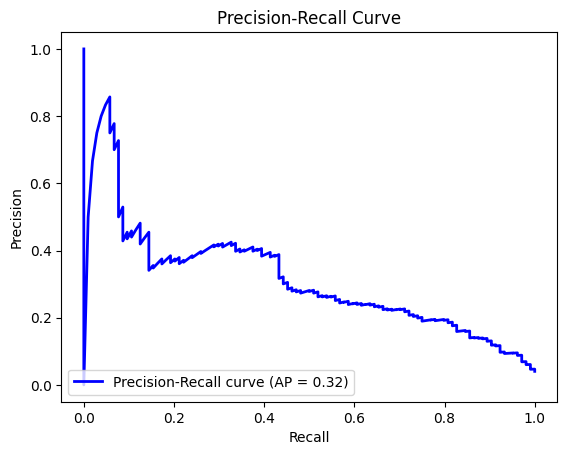

In [30]:
# Hacer curva Precision-Recall y calcular AUC
from sklearn.metrics import average_precision_score, precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
avg_precision = average_precision_score(y_test, y_pred_proba)

plt.figure()
plt.plot(recall, precision, color='blue', lw=2, label=f'Precision-Recall curve (AP = {avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

In [31]:
from sklearn.metrics import brier_score_loss, roc_auc_score

print("Prevalencia real de eventos:", y_test.mean())

probs_raw = rs_lgb.predict_proba(X_test)[:, 1]
print("AUC-ROC del modelo base:", roc_auc_score(y_test, probs_raw))
print("Brier Score del modelo base:", brier_score_loss(y_test, probs_raw))

Prevalencia real de eventos: 0.04043545878693624
AUC-ROC del modelo base: 0.8981657523999502
Brier Score del modelo base: 0.05862399230345693


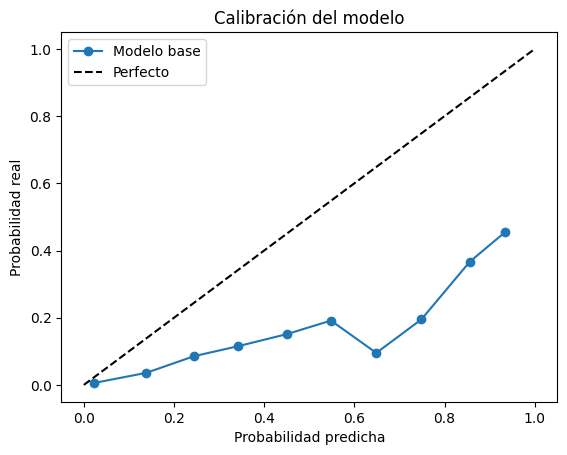

In [32]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, probs_raw, n_bins=10)

plt.plot(prob_pred, prob_true, "o-", label="Modelo base")
plt.plot([0, 1], [0, 1], "k--", label="Perfecto")
plt.xlabel("Probabilidad predicha")
plt.ylabel("Probabilidad real")
plt.title("Calibración del modelo")
plt.legend()
plt.show()

In [35]:
from sklearn.calibration import CalibratedClassifierCV

modelo_calibrado = CalibratedClassifierCV(
    estimator=rs_lgb.best_estimator_, 
    cv=5, 
    method='isotonic'
    )

modelo_calibrado.fit(X_train, y_train)

probs_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

print("=== EVALUACIÓN DEL MODELO CALIBRADO ===")
print(f"Prevalencia real de eventos: {y_test.mean():.2%}")
print(f"ROC-AUC (Base):       {roc_auc_score(y_test, probs_raw):.4f}")
print(f"ROC-AUC (Calibrado):  {roc_auc_score(y_test, probs_cal):.4f}")
print(f"Brier Score (Base):      {brier_score_loss(y_test, probs_raw):.4f} (menor es mejor)")
print(f"Brier Score (Calibrado): {brier_score_loss(y_test, probs_cal):.4f} (menor es mejor)")

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

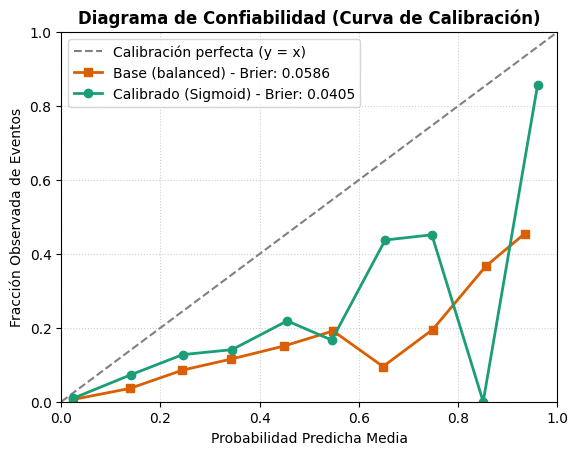

In [36]:
frac_pos_base, mean_pred_base = calibration_curve(y_test, probs_raw, n_bins=10, strategy='uniform')
frac_pos_cal, mean_pred_cal = calibration_curve(y_test, probs_cal, n_bins=10, strategy='uniform')

# 1. Diagrama de Confiabilidad

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibración perfecta (y = x)')
plt.plot(mean_pred_base, frac_pos_base, marker='s', linewidth=2, color='#d95f02', 
             label=f'Base (balanced) - Brier: {brier_score_loss(y_test, probs_raw):.4f}')
plt.plot(mean_pred_cal, frac_pos_cal, marker='o', linewidth=2, color='#1b9e77', 
             label=f'Calibrado (Sigmoid) - Brier: {brier_score_loss(y_test, probs_cal):.4f}')

plt.title('Diagrama de Confiabilidad (Curva de Calibración)', fontweight='bold')
plt.xlabel('Probabilidad Predicha Media')
plt.ylabel('Fracción Observada de Eventos')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)